# Лабораторная работа 9. Энкодерные модели, эмбеддинги и retrieval (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 3:** предобучение и представления

**Цель.** Разобрать двунаправленные модели (MLM) и контрастивное обучение представлений, на котором строятся поиск и RAG.

**Что нужно сдать:**
1. Маленький BERT, предобученный с MLM (маскирование 80/10/10), и каузальную модель того же размера; сравнение linear probing на классификации.
2. Bi-encoder, обученный InfoNCE с in-batch и hard negatives.
3. Эксперимент с температурой и размером батча; метрики alignment и uniformity.
4. Поиск с индексом и cross-encoder реранкингом; Recall@k, MRR, nDCG@10.
5. Минимальный RAG-пайплайн с предобученной LLM и анализ, когда извлечённый контекст помогает.

**Данные.** AG News: заголовок, краткое описание, одна из четырёх тем (World, Sports, Business, Sci/Tech). Пары «заголовок → описание» служат задачей поиска.

**Теория. InfoNCE.** Для запроса \(q\), положительного документа \(d^+\) и \(K-1\) негативов:
\[
\mathcal{L} = -\log\frac{\exp(s(q,d^+)/\tau)}{\sum_{j=1}^{K}\exp(s(q,d_j)/\tau)},\qquad I(q; d) \ge \log K - \mathcal{L}.
\]
**Alignment и uniformity** (Wang & Isola, 2020) для нормированных эмбеддингов:
\[
\ell_{align} = \mathbb{E}_{(x,y)\sim p_{pos}}\|f(x)-f(y)\|^2,\qquad
\ell_{unif} = \log\mathbb{E}_{x,y\sim p}\, e^{-2\|f(x)-f(y)\|^2}.
\]

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")


torch 2.6.0+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Данные и токенизация

In [2]:
import re, csv
from collections import Counter

def load_ag(split):
    path = download(f"https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/{split}.csv", f"ag_{split}.csv")
    rows = list(csv.reader(open(path, encoding="utf-8")))
    return [(int(r[0]) - 1, r[1].replace("\\", " "), r[2].replace("\\", " ")) for r in rows]

ag_train, ag_test = load_ag("train"), load_ag("test")
random.Random(0).shuffle(ag_train); random.Random(1).shuffle(ag_test)
N_PRE, N_PROBE, N_TEST = (20000, 2000, 1000) if FAST_DEV_RUN else (120000, 10000, 7600)
pre_end = min(N_PRE, len(ag_train) - N_PROBE)
pretrain, probe_train, test = ag_train[:pre_end], ag_train[pre_end:pre_end + N_PROBE], ag_test[:N_TEST]
assert pre_end > 0 and len(probe_train) == N_PROBE
# Словарь и предобучение используют pretrain; метки probe/test в них не участвуют.
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]

TOKEN_RE = re.compile(r"\w+|[^\w\s]")
def words(s): return TOKEN_RE.findall(s.lower())
SPECIALS = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
cnt = Counter(w for _, t, d in pretrain for w in words(t + " " + d))
itos = SPECIALS + [w for w, _ in cnt.most_common(8000 if FAST_DEV_RUN else 30000)]
stoi = {w: i for i, w in enumerate(itos)}; PAD, UNK, CLS, SEP, MASK = range(5); VOCAB = len(itos)
MAX_LEN = 48

def encode(text, max_len=MAX_LEN, cls=True):
    ids = ([CLS] if cls else []) + [stoi.get(w, UNK) for w in words(text)]
    return ids[:max_len]

def pad_batch(seqs):
    T = max(len(s) for s in seqs); x = torch.full((len(seqs), T), PAD)
    for i, s in enumerate(seqs): x[i, :len(s)] = torch.tensor(s)
    return x.to(DEVICE)
print(f"словарь {VOCAB}, пример: {encode(pretrain[0][1])[:15]}")


словарь 8005, пример: [2, 1, 75, 5, 143, 5, 65, 14, 1]


## 1. Энкодер и каузальная модель одинакового размера

Одна архитектура (Pre-RMSNorm, SwiGLU, обучаемые позиции) с флагом `causal`. Паддинг маскируется в attention.

In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d): super().__init__(); self.w = nn.Parameter(torch.ones(d))
    def forward(self, x): return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + 1e-6) * self.w

class Layer(nn.Module):
    def __init__(self, d, h):
        super().__init__(); self.h = h
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d)
        self.qkv, self.o = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False)
        hid = int(8 * d / 3); self.w1, self.w3, self.w2 = nn.Linear(d, hid, bias=False), nn.Linear(d, hid, bias=False), nn.Linear(hid, d, bias=False)
    def forward(self, x, pad_mask, causal):
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in self.qkv(self.n1(x)).split(C, 2))
        allowed = ~pad_mask[:, None, None, :]                                      # (B,1,1,T)
        if causal: allowed = allowed & torch.ones(T, T, dtype=torch.bool, device=x.device).tril()
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed)
        x = x + self.o(y.transpose(1, 2).reshape(B, T, C))
        z = self.n2(x); return x + self.w2(F.silu(self.w1(z)) * self.w3(z))

class Encoder(nn.Module):
    def __init__(self, vocab=VOCAB, d=128, n_layer=2 if FAST_DEV_RUN else 4, n_head=4, max_len=2 * MAX_LEN + 2, causal=False):
        super().__init__(); self.causal = causal
        self.emb = nn.Embedding(vocab, d); self.pos = nn.Parameter(torch.randn(max_len, d) * 0.02)
        self.layers = nn.ModuleList([Layer(d, n_head) for _ in range(n_layer)]); self.norm = RMSNorm(d)
        self.lm_head = nn.Linear(d, vocab, bias=False); self.lm_head.weight = self.emb.weight
        for mod in self.modules():                       # без этой инициализации (N(0,1) у эмбеддингов) обучение почти не идёт
            if isinstance(mod, (nn.Linear, nn.Embedding)): nn.init.normal_(mod.weight, std=0.02)
    def forward(self, x):
        pad = x == PAD; h = self.emb(x) + self.pos[: x.size(1)]
        for l in self.layers: h = l(h, pad, self.causal)
        return self.norm(h)
    def pool(self, x, how="mean"):
        h = self(x); m = (x != PAD).float()[..., None]
        if how == "mean": return (h * m).sum(1) / m.sum(1)
        if how == "cls": return h[:, 0]
        last = (x != PAD).sum(1) - 1; return h[torch.arange(len(x)), last]


## 2. Предобучение: MLM и causal LM

**MLM:** выберите 15% токенов (не специальных); из них 80% заменить на `[MASK]`, 10% — на случайный токен, 10% оставить. Loss — только на выбранных позициях.

In [4]:
def mask_tokens(x, p=0.15):
    # TODO: ваш код
    if not 0 <= p <= 1:
        raise ValueError("Вероятность маскирования должна лежать в [0, 1]")
    eligible = x >= len(SPECIALS)
    selected = (torch.rand(x.shape, device=x.device) < p) & eligible
    labels = x.clone().masked_fill(~selected, -100)
    corrupted = x.clone()
    choice = torch.rand(x.shape, device=x.device)
    to_mask = selected & (choice < 0.8)
    to_random = selected & (choice >= 0.8) & (choice < 0.9)
    corrupted[to_mask] = MASK
    random_words = torch.randint(len(SPECIALS), VOCAB, x.shape, device=x.device)
    corrupted[to_random] = random_words[to_random]
    # Оставшиеся 10% выбранных позиций сохраняют текст, но всё равно входят в loss.
    return corrupted, labels

x = pad_batch([encode(t + " " + d) for _, t, d in pretrain[:256]]); xm, lab = mask_tokens(x)
sel = lab != -100
print(f"доля выбранных: {sel.float().sum() / (x >= len(SPECIALS)).float().sum():.3f}; из них [MASK]: {(xm[sel] == MASK).float().mean():.2f}, без изменений: {(xm[sel] == x[sel]).float().mean():.2f}")


доля выбранных: 0.147; из них [MASK]: 0.80, без изменений: 0.10


165 c; MLM loss 5.415, CLM loss 4.875


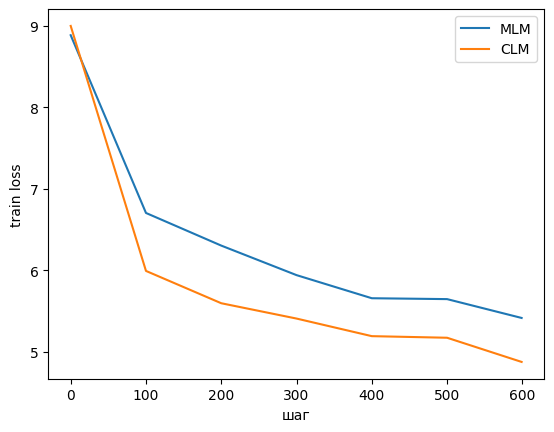

In [5]:
PRE_STEPS = 600 if FAST_DEV_RUN else 10000
pre_texts = [encode(t + " " + d) for _, t, d in pretrain]

def pretrain_model(causal, steps=PRE_STEPS, B=64, lr=3e-3, warmup=50):
    set_seed(); m = Encoder(causal=causal).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01); hist = []
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * s / steps)))
    for s in range(steps):
        x = pad_batch(random.sample(pre_texts, B))
        # TODO: ваш код (MLM — mask_tokens и loss по меткам; causal — сдвиг на один токен, паддинг игнорировать)
        if causal:
            h = m(x)[:, :-1]
            labels = x[:, 1:]
            selected = labels != PAD
        else:
            corrupted, labels = mask_tokens(x)
            h = m(corrupted)
            selected = labels != -100
        # Проекция на словарь нужна только там, где есть обучающая цель.
        # Это та же cross-entropy, что ignore_index, без logits для пропущенных позиций.
        loss = F.cross_entropy(m.lm_head(h[selected]), labels[selected]) if selected.any() else h.sum() * 0.0
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
        if s % 100 == 0 or s == steps - 1: hist.append(loss.item())
    return m, hist

t0 = time.time(); mlm, h1 = pretrain_model(False); clm, h2 = pretrain_model(True)
print(f"{time.time() - t0:.0f} c; MLM loss {h1[-1]:.3f}, CLM loss {h2[-1]:.3f}")

logged_steps = list(range(0, PRE_STEPS, 100))
if logged_steps[-1] != PRE_STEPS - 1: logged_steps.append(PRE_STEPS - 1)
plt.plot(logged_steps, h1, label="MLM"); plt.plot(logged_steps, h2, label="CLM")
plt.xlabel("шаг"); plt.ylabel("train loss"); plt.legend(); plt.show()
# MLM и CLM предсказывают разные позиции при разном контексте: их loss не является прямым сравнением качества.


## 3. Linear probing

Заморозьте модели, получите признаки (mean pooling; для каузальной модели также последний токен) и обучите логистическую регрессию на `probe_train`. Сравните с моделью со случайной инициализацией и с TF-IDF.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

@torch.no_grad()
def features(m, docs, how="mean", B=256):
    m.eval(); out = []
    for i in range(0, len(docs), B):
        out.append(m.pool(pad_batch([encode(t + " " + d) for _, t, d in docs[i:i + B]]), how).cpu())
    m.train(); return torch.cat(out).numpy()

def probe(Xtr, Xte):
    clf = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr, [y for y, _, _ in probe_train])
    return clf.score(Xte, [y for y, _, _ in test])

# TODO: ваш код (точность для MLM(mean), CLM(mean), CLM(last), random(mean), TF-IDF)

import pandas as pd
set_seed(); random_encoder = Encoder(causal=False).to(DEVICE)
probe_rows = []
for name, model, pooling in [("MLM(mean)", mlm, "mean"), ("CLM(mean)", clm, "mean"),
                              ("CLM(last)", clm, "last"), ("random(mean)", random_encoder, "mean")]:
    # features работает без градиентов; обучаются только коэффициенты sklearn-классификатора.
    accuracy = probe(features(model, probe_train, pooling), features(model, test, pooling))
    probe_rows.append({"признаки": name, "accuracy": accuracy})
probe_vectorizer = TfidfVectorizer(min_df=2, max_features=50000, ngram_range=(1, 2))
X_probe = probe_vectorizer.fit_transform([t + " " + d for _, t, d in probe_train])
X_test = probe_vectorizer.transform([t + " " + d for _, t, d in test])
probe_rows.append({"признаки": "TF-IDF", "accuracy": probe(X_probe, X_test)})
probe_df = pd.DataFrame(probe_rows); display(probe_df.round(4))


,признаки,accuracy
0,MLM(mean),0.777
1,CLM(mean),0.697
2,CLM(last),0.537
3,random(mean),0.501
4,TF-IDF,0.866


## 4. Bi-encoder с InfoNCE

Запрос — заголовок, документ — описание. Общий энкодер, инициализированный MLM-моделью, mean pooling, L2-нормировка, сходство — скалярное произведение. Hard negative для каждого запроса — ближайшее по TF-IDF **чужое** описание.

In [7]:
import copy
pairs = [(encode(t), encode(d), y) for y, t, d in pretrain]
tfidf = TfidfVectorizer(min_df=2, max_features=50000).fit([d for _, _, d in pretrain])
D_mat = tfidf.transform([d for _, _, d in pretrain]); Q_mat = tfidf.transform([t for _, t, _ in pretrain])

def hard_negatives(Q, D, chunk=2000):
    # TODO: ваш код (для каждого запроса — argmax сходства по документам, исключая собственный)
    if Q.shape[0] != D.shape[0] or D.shape[0] < 2:
        raise ValueError("Нужны выровненные запросы/документы и хотя бы два документа")
    result = np.empty(Q.shape[0], dtype=np.int64)
    Q, D = Q.astype(np.float32), D.astype(np.float32)
    for start in range(0, Q.shape[0], chunk):
        stop = min(start + chunk, Q.shape[0])
        scores = (Q[start:stop] @ D.T).toarray()
        scores[np.arange(stop - start), np.arange(start, stop)] = -np.inf
        result[start:stop] = scores.argmax(1)
    # Собственный документ исключён даже при нулевом сходстве со всеми кандидатами.
    return result

hard_neg = hard_negatives(Q_mat, D_mat)
print("пример: ", pretrain[0][1], "|| hard neg:", pretrain[hard_neg[0]][2][:100])

def encode_norm(m, x): return F.normalize(m.pool(x), dim=-1)

def info_nce(q, d, tau, d_hard=None):
    # TODO: ваш код
    if tau <= 0:
        raise ValueError("Температура должна быть положительной")
    logits = q @ d.T
    if d_hard is not None:
        # B батчевых документов плюс один собственный hard negative каждого запроса.
        logits = torch.cat([logits, (q * d_hard).sum(-1, keepdim=True)], dim=1)
    target = torch.arange(len(q), device=q.device)
    return F.cross_entropy(logits / tau, target)

def train_biencoder(tau=0.05, B=64, steps=300 if FAST_DEV_RUN else 3000, use_hard=True, init=None, lr=3e-4):
    set_seed(); m = copy.deepcopy(init or mlm); opt = torch.optim.AdamW(m.parameters(), lr=lr)
    for s in range(steps):
        idx = random.sample(range(len(pairs)), B)
        q = encode_norm(m, pad_batch([pairs[i][0] for i in idx])); d = encode_norm(m, pad_batch([pairs[i][1] for i in idx]))
        dh = encode_norm(m, pad_batch([pairs[hard_neg[i]][1] for i in idx])) if use_hard else None
        loss = info_nce(q, d, tau, dh); opt.zero_grad(); loss.backward(); opt.step()
    return m

t0 = time.time(); bienc = train_biencoder(); print(f"{time.time() - t0:.0f} c")


пример:  Xerces 2.6.1 and BOM || hard neg: InfoWorld - Plumtree Software further extended its portal-based, Web applications building and manag


46 c


## 5. Метрики поиска

Индекс — матрица нормированных эмбеддингов всех описаний тестовой выборки. Для каждого заголовка единственный релевантный документ — его описание. Посчитайте Recall@1/5/10, MRR и nDCG@10 (\(\mathrm{nDCG} = 1/\log_2(r+1)\) при ранге \(r \le 10\)).

In [8]:
@torch.no_grad()
def embed_texts(m, texts, B=256):
    m.eval(); out = [encode_norm(m, pad_batch([encode(t) for t in texts[i:i + B]])).cpu() for i in range(0, len(texts), B)]
    m.train(); return torch.cat(out)

def retrieval_metrics(S):
    """S: (n_q, n_d), правильный документ для запроса i — документ i."""
    # TODO: ваш код
    S = torch.as_tensor(S)
    if S.ndim != 2 or not len(S) or S.size(1) < S.size(0) or torch.isnan(S).any():
        raise ValueError("Нужна непустая матрица без NaN с правильным документом i")
    order = torch.argsort(S, dim=1, descending=True, stable=True)
    correct = torch.arange(len(S), device=S.device)
    rank = (order == correct[:, None]).long().argmax(1).float() + 1
    # После rerank отсутствующий в top-k правильный документ имеет -inf: это промах.
    available = torch.isfinite(S[correct, correct])
    inverse_rank = torch.where(available, 1 / rank, torch.zeros_like(rank))
    result = {f"Recall@{k}": ((rank <= k) & available).float().mean().item() for k in (1, 5, 10)}
    result["MRR"] = inverse_rank.mean().item()
    result["nDCG@10"] = torch.where(available & (rank <= 10), 1 / torch.log2(rank + 1), 0.0).mean().item()
    return result

q_texts, d_texts = [t for _, t, _ in test], [d for _, _, d in test]
import pandas as pd
res = {"TF-IDF": retrieval_metrics(torch.tensor((tfidf.transform(q_texts) @ tfidf.transform(d_texts).T).toarray()))}
res["MLM без дообучения"] = retrieval_metrics(embed_texts(mlm, q_texts) @ embed_texts(mlm, d_texts).T)
res["bi-encoder"] = retrieval_metrics(embed_texts(bienc, q_texts) @ embed_texts(bienc, d_texts).T)
pd.DataFrame(res).T.round(3)


,Recall@1,Recall@5,Recall@10,MRR,nDCG@10
TF-IDF,0.634,0.775,0.808,0.697,0.721
MLM без дообучения,0.020,0.064,0.111,0.053,0.057
bi-encoder,0.277,0.479,0.570,0.376,0.414


## 6. Температура, размер батча, alignment и uniformity

Обучите bi-encoder при \(\tau \in \{0.01, 0.05, 0.2, 1.0\}\) (батч 64) и при батчах 16 и 128 (\(\tau = 0.05\)), без hard negatives. Для каждой модели посчитайте MRR, \(\ell_{align}\) и \(\ell_{unif}\) на тестовых парах и нанесите модели на плоскость \((\ell_{unif}, \ell_{align})\).

,tau,batch,MRR,align,uniform
0,0.01,64,0.275,0.163,-0.566
1,0.05,64,0.347,0.720,-2.574
2,0.20,64,0.297,0.763,-3.217
3,1.00,64,0.106,0.391,-2.029
4,0.05,16,0.188,0.463,-1.615
5,0.05,128,0.418,0.808,-2.976


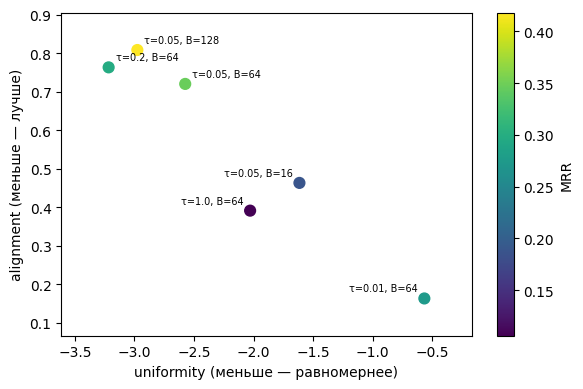

In [9]:
def align_uniform(m, n=1000):
    # TODO: ваш код
    n = min(n, len(test))
    if n < 2: raise ValueError("Нужны хотя бы две положительные пары")
    q = embed_texts(m, [t for _, t, _ in test[:n]]).float()
    d = embed_texts(m, [t for _, _, t in test[:n]]).float()
    alignment = (q - d).square().sum(-1).mean()
    pooled = torch.cat([q, d])
    # pdist не включает самопары и не дублирует (i,j)/(j,i).
    log_values = -2 * torch.pdist(pooled).square()
    uniformity = torch.logsumexp(log_values, dim=0) - math.log(log_values.numel())
    return alignment.item(), uniformity.item()

AB_STEPS = 200 if FAST_DEV_RUN else 2000
configs = [(t, 64) for t in (0.01, 0.05, 0.2, 1.0)] + [(0.05, 16), (0.05, 128)]
rows = []
for tau, B in configs:
    m = train_biencoder(tau=tau, B=B, steps=AB_STEPS, use_hard=False)
    a, u = align_uniform(m); mrr = retrieval_metrics(embed_texts(m, q_texts) @ embed_texts(m, d_texts).T)["MRR"]
    rows.append({"tau": tau, "batch": B, "MRR": mrr, "align": a, "uniform": u})
au = pd.DataFrame(rows); display(au.round(3))
# На графике используем ту же точность, что в показанной таблице.
plot_au = au.round(3)
plt.figure(figsize=(6, 4))
sc = plt.scatter(plot_au.uniform, plot_au["align"], c=plot_au.MRR, cmap="viridis", s=60)
for _, r in plot_au.iterrows():
    right = r.uniform > plot_au.uniform.median()
    plt.annotate(f"τ={r.tau}, B={int(r.batch)}", (r.uniform, r["align"]),
                 xytext=(-5 if right else 5, 5), textcoords="offset points",
                 ha="right" if right else "left", fontsize=7)
plt.margins(x=0.15, y=0.15)
plt.colorbar(sc, label="MRR"); plt.xlabel("uniformity (меньше — равномернее)"); plt.ylabel("alignment (меньше — лучше)")
plt.tight_layout(); plt.show()


## 7. Cross-encoder и реранкинг

Cross-encoder получает `[CLS] заголовок [SEP] описание` и выдаёт скаляр релевантности (линейный слой над mean pooling; `[CLS]` при MLM-предобучении не обучался). Обучите его со списочной функцией потерь: для каждого запроса кандидаты — позитив, hard negative и 6 случайных документов, loss — кросс-энтропия softmax по кандидатам с позитивом на первом месте. Переранжируйте top-20 bi-encoder двумя способами:
1. только по оценке cross-encoder;
2. по смеси \(z(s_{bi}) + \lambda z(s_{ce})\), где \(z\) — нормировка оценок внутри top-20 каждого запроса, \(\lambda \in \{0.25, 0.5, 1\}\).

In [10]:
class CrossEncoder(nn.Module):
    def __init__(self, enc):
        super().__init__(); self.enc = copy.deepcopy(enc); self.score = nn.Linear(enc.emb.embedding_dim, 1)
    def forward(self, q_ids, d_ids):
        x = pad_batch([q + [SEP] + [t for t in d if t != CLS][:MAX_LEN] for q, d in zip(q_ids, d_ids)])
        h = self.enc(x); m = (x != PAD).float()[..., None]
        return self.score((h * m).sum(1) / m.sum(1)).squeeze(-1)

def train_cross(steps=200 if FAST_DEV_RUN else 3000, B=16, n_rand=6):
    set_seed(); ce = CrossEncoder(mlm).to(DEVICE); opt = torch.optim.AdamW(ce.parameters(), lr=3e-4)
    # TODO: ваш код (для каждого запроса 1 позитив + 1 hard negative + n_rand случайных; cross_entropy по кандидатам, метка 0)
    n_candidates = 2 + n_rand
    for step in range(steps):
        query_ids, document_ids = [], []
        for index in random.sample(range(len(pairs)), B):
            hard_index = int(hard_neg[index])
            random_ids = []
            while len(random_ids) < n_rand:
                candidate = random.randrange(len(pairs))
                if candidate not in {index, hard_index} and candidate not in random_ids:
                    random_ids.append(candidate)
            candidates = [index, hard_index] + random_ids
            query_ids.extend([pairs[index][0]] * n_candidates)
            document_ids.extend(pairs[j][1] for j in candidates)
        scores = ce(query_ids, document_ids).reshape(B, n_candidates)
        loss = F.cross_entropy(scores, torch.zeros(B, dtype=torch.long, device=DEVICE))
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(ce.parameters(), 1.0); opt.step()
    return ce

@torch.no_grad()
def rerank(S, ce, k=20, lam=None):
    """lam=None — только cross-encoder; иначе z(bi) + lam * z(ce) внутри top-k. Документы вне top-k получают -inf."""
    # TODO: ваш код
    if k < 1: raise ValueError("k должен быть положительным")
    k = min(k, S.size(1))
    # Три смеси используют те же оценки CE. Пересчитываем их при изменении S, текста или весов.
    versions = tuple(p._version for p in ce.parameters())
    key = (S._version, k, versions, tuple(q_texts), tuple(d_texts))
    cache = getattr(ce, "_rerank_cache", None)
    if cache is not None and cache[0] is S and cache[1] == key:
        top_indices, cross_scores = cache[2], cache[3]
    else:
        top_indices = S.argsort(dim=1, descending=True, stable=True)[:, :k]
        q_ids, d_ids = [encode(t) for t in q_texts], [encode(t) for t in d_texts]
        cross_scores = torch.empty(S.size(0) * k, dtype=torch.float32)
        was_training = ce.training; ce.eval()
        try:
            flat_docs = top_indices.cpu().flatten().tolist()
            for start in range(0, len(flat_docs), 128):
                stop = min(start + 128, len(flat_docs))
                q_batch = [q_ids[i // k] for i in range(start, stop)]
                d_batch = [d_ids[flat_docs[i]] for i in range(start, stop)]
                cross_scores[start:stop] = ce(q_batch, d_batch).float().cpu()
        finally:
            ce.train(was_training)
        cross_scores = cross_scores.reshape(S.size(0), k).to(S.device)
        ce._rerank_cache = (S, key, top_indices, cross_scores)
    bi_scores = S.gather(1, top_indices)
    def z(scores):
        return (scores - scores.mean(1, keepdim=True)) / scores.std(1, unbiased=False, keepdim=True).clamp_min(1e-6)
    scores = cross_scores if lam is None else z(bi_scores) + lam * z(cross_scores)
    result = torch.full_like(S, -torch.inf)
    return result.scatter(1, top_indices, scores.to(S.dtype))

t0 = time.time(); cross = train_cross(); print(f"cross-encoder: {time.time() - t0:.0f} c")
S_bi = embed_texts(bienc, q_texts) @ embed_texts(bienc, d_texts).T
res["+ cross-encoder (только CE)"] = retrieval_metrics(rerank(S_bi, cross))
for lam in (0.25, 0.5, 1.0): res[f"+ смесь bi + {lam}·CE"] = retrieval_metrics(rerank(S_bi, cross, lam=lam))
pd.DataFrame(res).T.round(3)


cross-encoder: 41 c


,Recall@1,Recall@5,Recall@10,MRR,nDCG@10
TF-IDF,0.634,0.775,0.808,0.697,0.721
MLM без дообучения,0.020,0.064,0.111,0.053,0.057
bi-encoder,0.277,0.479,0.570,0.376,0.414
+ cross-encoder (только CE),0.058,0.233,0.385,0.153,0.193
+ смесь bi + 0.25·CE,0.278,0.484,0.569,0.372,0.415
+ смесь bi + 0.5·CE,0.263,0.475,0.558,0.361,0.404
+ смесь bi + 1.0·CE,0.233,0.446,0.548,0.331,0.377


## 8. Минимальный RAG

Предобученная instruct-LLM классифицирует тему заголовка. Сравните четыре варианта контекста:
1. без контекста (zero-shot);
2. 4 случайных размеченных примера;
3. 4 ближайших по bi-encoder размеченных примера из обучающей выборки (retrieval);
4. 4 ближайших примера с **перепутанными** метками.

Ответ выбирается по максимуму логита первого токена названия класса после промпта (а не свободной генерацией), чтобы исключить ошибки формата; первые токены четырёх классов различаются. Используется базовая (не instruct) модель с обычным few-shot-промптом: в контрольных прогонах шаблон чата у маленьких instruct-моделей давал точность на уровне случайной. В `FAST_DEV_RUN` — SmolLM2-360M, в полном режиме — Qwen2.5-1.5B.

In [11]:
# ==== Загрузка предобученных моделей Hugging Face ====
from transformers import AutoTokenizer, AutoModelForCausalLM

def load_lm(name, dtype=None):
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    dtype = dtype or (torch.float16 if DEVICE == "cuda" else torch.float32)
    try:
        model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype)
    return model.to(DEVICE).eval(), tok

@torch.no_grad()
def perplexity(model, tok, text, max_len=512, stride=256, max_windows=None):
    ids = tok(text, return_tensors="pt").input_ids.to(DEVICE)
    nll, cnt, prev = 0.0, 0, 0
    for i, start in enumerate(range(0, ids.size(1) - 1, stride)):
        if max_windows and i >= max_windows: break
        end = min(start + max_len, ids.size(1)); x = ids[:, start:end]
        tgt = x.clone(); tgt[:, : max(0, prev - start)] = -100
        out = model(x, labels=tgt)
        n = (tgt[:, 1:] != -100).sum().item(); nll += out.loss.float().item() * n; cnt += n; prev = end
        if end == ids.size(1): break
    return math.exp(nll / cnt)


C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.4.3)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(
C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
LLM_NAME = "HuggingFaceTB/SmolLM2-360M" if FAST_DEV_RUN else "Qwen/Qwen2.5-1.5B"
llm, llm_tok = load_lm(LLM_NAME)
N_RAG = 80 if FAST_DEV_RUN else 1000
kb = probe_train; kb_emb = embed_texts(bienc, [t for _, t, _ in kb])
CLASS_FIRST = [llm_tok(" " + c, add_special_tokens=False).input_ids[0] for c in CLASSES]
assert len(set(CLASS_FIRST)) == 4, "первые токены классов должны различаться"

def build_prompt(title, examples):
    shots = "".join(f"Headline: {t}\nTopic: {CLASSES[y]}\n\n" for y, t in examples)
    return "Classify the news headline into one of the topics: World, Sports, Business, Sci/Tech.\n\n" + shots + f"Headline: {title}\nTopic:"

@torch.no_grad()
def classify(prompt):
    # TODO: ваш код (один прямой проход; сравните логиты первых токенов " World", " Sports", " Business", " Sci")
    single = isinstance(prompt, str)
    prompts = [prompt] if single else list(prompt)
    if not prompts: return []
    llm_tok.padding_side = "left"; llm_tok.truncation_side = "left"
    inputs = llm_tok(prompts, return_tensors="pt", padding=True, truncation=True,
                     max_length=min(2048, llm.config.max_position_embeddings)).to(DEVICE)
    positions = inputs.attention_mask.cumsum(-1) - 1
    positions.masked_fill_(inputs.attention_mask == 0, 0)
    import inspect
    supported = inspect.signature(llm.forward).parameters
    extra = {"logits_to_keep": 1} if "logits_to_keep" in supported else ({"num_logits_to_keep": 1} if "num_logits_to_keep" in supported else {})
    logits = llm(**inputs, position_ids=positions, use_cache=False, **extra).logits[:, -1]
    prediction = logits[:, CLASS_FIRST].argmax(-1).cpu().tolist()
    return prediction[0] if single else prediction

# TODO: ваш код (точность для четырёх вариантов контекста)

rag_cases = test[:min(N_RAG, len(test))]
rag_titles = [t for _, t, _ in rag_cases]
nearest = (embed_texts(bienc, rag_titles) @ kb_emb.T).topk(4, dim=1).indices.tolist()
rng = random.Random(SEED)
variants = ["zero-shot", "random 4", "retrieval 4", "retrieval 4, неверные метки"]
records = []
for index, (_, title, _) in enumerate(rag_cases):
    random_examples = [(kb[i][0], kb[i][1]) for i in rng.sample(range(len(kb)), 4)]
    retrieved = [(kb[i][0], kb[i][1]) for i in nearest[index]]
    # Меняем каждую метку на неверную: перестановка одинаковых меток могла бы ничего не изменить.

    corrupted = [((label + rng.randrange(1, len(CLASSES))) % len(CLASSES), t) for label, t in retrieved]
    for variant, examples in enumerate([[], random_examples, retrieved, corrupted]):
        records.append((variant, index, build_prompt(title, examples)))
# Группировка по длине уменьшает padding, не меняя примеры и их порядок внутри промпта.
records.sort(key=lambda item: len(item[2]))
rag_predictions = np.full((len(variants), len(rag_cases)), -1, dtype=int)
RAG_BATCH = 4 if FAST_DEV_RUN else 8
for start in range(0, len(records), RAG_BATCH):
    batch = records[start:start + RAG_BATCH]
    predictions = classify([item[2] for item in batch])
    for (variant, index, _), prediction in zip(batch, predictions):
        rag_predictions[variant, index] = prediction
    if start % (10 * RAG_BATCH) == 0: print(f"RAG: {min(start + RAG_BATCH, len(records))}/{len(records)} промптов", flush=True)
assert (rag_predictions >= 0).all()
targets = np.array([label for label, _, _ in rag_cases])
rag_df = pd.DataFrame([{"контекст": name, "верных": int((rag_predictions[i] == targets).sum()),
                         "примеров": len(targets), "accuracy": float((rag_predictions[i] == targets).mean())}
                        for i, name in enumerate(variants)])
display(rag_df)
print("Модель:", LLM_NAME, "; revision:", getattr(llm.config, "_commit_hash", None))
print("Проверены одни и те же заголовки. KB содержит только probe_train; тестовые метки не попадают в промпты.")


RAG: 4/320 промптов


RAG: 44/320 промптов


RAG: 84/320 промптов


RAG: 124/320 промптов


RAG: 164/320 промптов


RAG: 204/320 промптов


RAG: 244/320 промптов


RAG: 284/320 промптов


,контекст,верных,примеров,accuracy
0,zero-shot,47,80,0.5875
1,random 4,32,80,0.4000
2,retrieval 4,51,80,0.6375
3,"retrieval 4, неверные метки",19,80,0.2375


Модель: HuggingFaceTB/SmolLM2-360M ; revision: f8027fd0eaeea54caa13c31d31b9fdc459c38b49
Проверены одни и те же заголовки. KB содержит только probe_train; тестовые метки не попадают в промпты.


## Вопросы

1. Докажите неравенство \(I(q; d) \ge \log K - \mathcal{L}_{InfoNCE}\) (набросок) и объясните, почему большой батч полезен.
2. Как температура влияет на градиенты по hard negatives? Почему слишком малая \(\tau\) вредна?
3. Почему MLM-модель даёт лучшие признаки для классификации, чем каузальная того же размера? Почему для каузальной модели важно, какой токен брать?
4. В чём компромисс bi-encoder и cross-encoder по качеству и стоимости? Почему реранкинг применяют только к top-k?
5. По результатам п. 8: когда извлечённый контекст помогает, а когда мешает? Что показывает эксперимент с перепутанными метками о механизме in-context learning у вашей модели?

### Ответы

1. Угадываем индекс положительной пары среди K кандидатов с независимыми негативами из p(d). Индекс имеет энтропию $\log K$, а cross-entropy не меньше условной энтропии; отсюда $\log K-L\le I(\text{индекс};q,\text{кандидаты})\le I(q;d)$. Большой батч даёт больше негативов и потолок $\log K$, но дороже и содержит ложные негативы. Для зависимых/hard negatives исходное доказательство автоматически неприменимо. [van den Oord et al., 2018](https://arxiv.org/abs/1807.03748).

2. Градиент сходства равен $(p_j-\mathbb{1}[j=+])/\tau$: малая tau усиливает влияние похожих негативов, шум и ошибки. В `au` при B=64 лучшая проверенная tau=0.05 (MRR 0.347); у tau=0.01 alignment 0.163, uniformity -0.566 и MRR 0.275: одного сближения пар мало. Батч 128 дал MRR 0.418, 16 — 0.188; при фиксированных шагах большой батч также обработал больше примеров. Универсального лучшего tau нет.

3. MLM видит оба направления; CLM(last) — весь префикс, ранние позиции — его части, начальный CLS не видит документ. Поэтому pooling проверяется отдельно. В `probe_df` accuracy MLM(mean)/CLM(mean)/CLM(last)/random/TF-IDF: 0.777/0.697/0.537/0.501/0.866. Энкодеры при probing фиксированы, обучается линейный классификатор. Преимущество MLM над CLM не универсально; их pretraining loss напрямую несопоставим.

4. Bi-encoder позволяет заранее построить индекс; cross-encoder заново обрабатывает каждую пару, поэтому применяется к top-20. Отсутствующий правильный документ даёт нулевой MRR/nDCG. Контрастивное обучение подняло MRR с 0.053 до 0.376, TF-IDF дал 0.697; чистый CE после 200 шагов — 0.153. Смесь lambda=0.25 дала Recall@1 0.278 против 0.277. Небольшой спад MRR смеси нельзя целиком приписать ранжированию: документы вне top-20 отсечены.

5. В `rag_df` из 80 заголовков правильно: без примеров 47 (58.75%), со случайными 32 (40%), с найденными 51 (63.75%), с неверными метками 19 (23.75%). Retrieval добавил четыре ответа — предварительный результат малой выборки. Контроль сохраняет заголовки контекста, меняя каждую метку на другой класс: ошибки показывают чувствительность к примерам, не конкретный механизм ICL. Используется базовая SmolLM2, few-shot и логит первого токена класса; нерелевантный или неверно размеченный контекст может мешать.
